# Этап 6. Эпизоды: исходы, пробег, «лишние» срабатывания фильтра

Код: `classify_outcome`, `run_episode` в `rssrl/scenarios.py`; `interventions`, `counterfactual`, `counterfactual_grid` в `rssrl/pilot.py`. Проверки: `tests/test_episodes.py`.

**Исход эпизода** (highway-v0 ограничен 40 с), в порядке приоритета:
- *столкновение* — агент столкнулся (эпизод на этом заканчивается);
- *съезд с дороги* — агент хотя бы раз оказался вне дороги;
- *остановка* — агент стоял (скорость < 0,5 м/с) не меньше 2 с подряд;
- *безопасно* — доехал до конца времени без всего перечисленного.

**Пробег** — сколько агент проехал по факту, до конца времени или до столкновения.

**Контрфактическая проверка.** Каждое вмешательство фильтра (торможение или запрет/отмена перестроения) проверяем так: заново прогоняем ту же сцену с той же политикой, но с момента вмешательства фильтр отключен — на все время вмешательства и еще 5 с после. До этого момента прогон совпадает с исходным (сцена детерминирована своим seed — это проверяет тест). Если в этом окне агент столкнулся бы — вмешательство **нужное**, если нет — **лишнее**.

Вмешательства с перерывом меньше 1 с считаем одним: иначе «дребезг» фильтра на границе d_min (+3/−4 м/с² через шаг) дал бы сотни коротких вмешательств.

In [1]:
import sys
sys.path.insert(0, '..')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rssrl.pilot import run_grid, counterfactual_grid, _run_one, MERGE_GAP, CF_HORIZON

FIG = Path('..') / 'results' / 'figures'
PILOT = Path('..') / 'results' / 'pilot_06'  # таблицы пилота, в git не идут
PILOT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
SEEDS = range(20)
VARIANTS = [(False, 0.0), (True, 0.0), (True, 0.5)]
NAMES = {(False, 0.0): 'без фильтра', (True, 0.0): 'фильтр, задержка 0',
         (True, 0.5): 'фильтр, задержка ρ'}
# (сценарий, уровни, политика, подпись)
SETUPS = [
    ('nominal', [1.0], 'idle', 'номинальный, IDLE'),
    ('nominal', [1.0], 'random', 'номинальный, случайная'),
    ('brake', [1.0, 2.0], 'idle', 'тормозящий лидер, IDLE'),
    ('cutin', [1.0, 0.25], 'idle', 'подрезание, IDLE'),
]

## Исходы эпизодов и пробег

In [2]:
frames, LOGS = [], {}
for kind, levels, policy, label in SETUPS:
    o, logs = run_grid(SEEDS, levels, VARIANTS, kind=kind, policy=policy)
    o['сценарий'] = label
    o['уровень'] = o['gamma'] if kind == 'cutin' else o['beta']
    frames.append(o)
    LOGS[label] = (kind, policy, logs)
outcomes = pd.concat(frames, ignore_index=True)
outcomes['вариант'] = [NAMES[(s, d)] for s, d in zip(outcomes['shield'], outcomes['reaction_delay'])]
outcomes.drop(columns=['crash_partners']).to_csv(PILOT / 'outcomes.csv', index=False)

table = (outcomes.groupby(['сценарий', 'уровень', 'вариант'], sort=False)['outcome']
         .value_counts().unstack(fill_value=0)
         .reindex(columns=['safe', 'stopped', 'offroad', 'collision'], fill_value=0)
         .rename(columns={'safe': 'безопасно', 'stopped': 'остановка',
                          'offroad': 'съезд', 'collision': 'столкновение'}))
table['пробег, км (среднее)'] = outcomes.groupby(['сценарий', 'уровень', 'вариант'], sort=False)['distance_km'].mean().round(3)
table

outcome                                            безопасно  остановка  \
сценарий               уровень вариант                                    
номинальный, IDLE      1.00    без фильтра                 2          0   
                               фильтр, задержка 0         20          0   
                               фильтр, задержка ρ         20          0   
номинальный, случайная 1.00    без фильтра                 2          0   
                               фильтр, задержка 0         20          0   
                               фильтр, задержка ρ         20          0   
тормозящий лидер, IDLE 1.00    без фильтра                 0          0   
                               фильтр, задержка 0          0         20   
                               фильтр, задержка ρ          0         20   
                       2.00    без фильтра                 0          0   
                               фильтр, задержка 0          0         13   
                               фильтр, задержка ρ          0          0   
подрезание, IDLE       1.00    без фильтра                 0          0   
                               фильтр, задержка 0          9         11   
                               фильтр, задержка ρ          9         11   
                       0.25    без фильтра                 0          0   
                               фильтр, задержка 0          5          7   
                               фильтр, задержка ρ          4          0   

outcome                                            съезд  столкновение  \
сценарий               уровень вариант                                   
номинальный, IDLE      1.00    без фильтра             0            18   
                               фильтр, задержка 0      0             0   
                               фильтр, задержка ρ      0             0   
номинальный, случайная 1.00    без фильтра             0            18   
                               фильтр, задержка 0      0             0   
                               фильтр, задержка ρ      0             0   
тормозящий лидер, IDLE 1.00    без фильтра             0            20   
                               фильтр, задержка 0      0             0   
                               фильтр, задержка ρ      0             0   
                       2.00    без фильтра             0            20   
                               фильтр, задержка 0      0             7   
                               фильтр, задержка ρ      0            20   
подрезание, IDLE       1.00    без фильтра             0            20   
                               фильтр, задержка 0      0             0   
                               фильтр, задержка ρ      0             0   
                       0.25    без фильтра             0            20   
                               фильтр, задержка 0      0             8   
                               фильтр, задержка ρ      0            16   

outcome                                            пробег, км (среднее)  
сценарий               уровень вариант                                   
номинальный, IDLE      1.00    без фильтра                        0.538  
                               фильтр, задержка 0                 0.892  
                               фильтр, задержка ρ                 0.895  
номинальный, случайная 1.00    без фильтра                        0.372  
                               фильтр, задержка 0                 0.858  
                               фильтр, задержка ρ                 0.870  
тормозящий лидер, IDLE 1.00    без фильтра                        0.315  
                               фильтр, задержка 0                 0.323  
                               фильтр, задержка ρ                 0.321  
                       2.00    без фильтра                        0.296  
                               фильтр, задержка 0                 0.302  
                               фильтр, задержка ρ       

Как читать таблицу (уровень — β для тормозящего лидера, γ для подрезания, в номинальном режиме не используется):
- **Остановка** — главный новый исход. Тормозящий лидер останавливается и стоит, поэтому IDLE с фильтром, если не врезался, останавливается за ним и стоит до конца эпизода. Это безопасно, но агент никуда не едет. Без категории «остановка» такие эпизоды попали бы в «безопасно» и приукрасили бы результат.
- **Съезд с дороги** не встретился ни разу: агент highway-env перестраивается только между существующими полосами.
- **Пробег** меньше там, где агент врезается рано (без фильтра) или стоит.

## Контрфактическая проверка вмешательств

In [3]:
cf_frames = []
for label, (kind, policy, logs) in LOGS.items():
    cf = counterfactual_grid(logs, kind=kind, policy=policy)
    cf['сценарий'] = label
    cf_frames.append(cf)
cf = pd.concat(cf_frames, ignore_index=True)
cf['вариант'] = [NAMES[(True, d)] for d in cf['reaction_delay']]
cf['тип'] = np.where(cf['brake_steps'] > 0, 'торможение', 'только перестроение')
cf.drop(columns=['crash_partners']).to_csv(PILOT / 'counterfactual.csv', index=False)

cf_table = cf.groupby(['сценарий', 'level', 'вариант'], sort=False).agg(
    вмешательств=('needed', 'size'),
    нужных=('needed', 'sum'),
    длительность_с=('duration', 'mean'),
)
cf_table['доля нужных'] = (cf_table['нужных'] / cf_table['вмешательств']).round(2)
cf_table.round(1)

вмешательств  нужных  \
сценарий               level вариант                                    
номинальный, IDLE      1.00  фильтр, задержка 0            29      20   
                             фильтр, задержка ρ            27      19   
номинальный, случайная 1.00  фильтр, задержка 0           165      48   
                             фильтр, задержка ρ           153      57   
тормозящий лидер, IDLE 1.00  фильтр, задержка 0            27      20   
                             фильтр, задержка ρ            27      20   
                       2.00  фильтр, задержка 0            27      20   
                             фильтр, задержка ρ            27      20   
подрезание, IDLE       1.00  фильтр, задержка 0            30      20   
                             фильтр, задержка ρ            31      20   
                       0.25  фильтр, задержка 0            30      20   
                             фильтр, задержка ρ            30      20   

                                                 длительность_с  доля нужных  
сценарий               level вариант                                          
номинальный, IDLE      1.00  фильтр, задержка 0            20.9          0.7  
                             фильтр, задержка ρ            22.2          0.7  
номинальный, случайная 1.00  фильтр, задержка 0             1.8          0.3  
                             фильтр, задержка ρ             1.9          0.4  
тормозящий лидер, IDLE 1.00  фильтр, задержка 0            23.4          0.7  
                             фильтр, задержка ρ            23.2          0.7  
                       2.00  фильтр, задержка 0            15.2          0.7  
                             фильтр, задержка ρ             4.0          0.7  
подрезание, IDLE       1.00  фильтр, задержка 0            19.3          0.7  
                             фильтр, задержка ρ            17.9          0.6  
                       0.25  фильтр, задержка 0            13.0          0.7  
                             фильтр, задержка ρ             7.3          0.7

In [4]:
by_type = cf.groupby(['сценарий', 'тип'], sort=False).agg(
    вмешательств=('needed', 'size'), нужных=('needed', 'sum'))
by_type['доля нужных'] = (by_type['нужных'] / by_type['вмешательств']).round(2)
by_type

вмешательств  нужных  доля нужных
сценарий               тип                                                   
номинальный, IDLE      торможение                     56      39         0.70
номинальный, случайная торможение                    194      73         0.38
                       только перестроение           124      32         0.26
тормозящий лидер, IDLE торможение                    108      80         0.74
подрезание, IDLE       торможение                    121      80         0.66

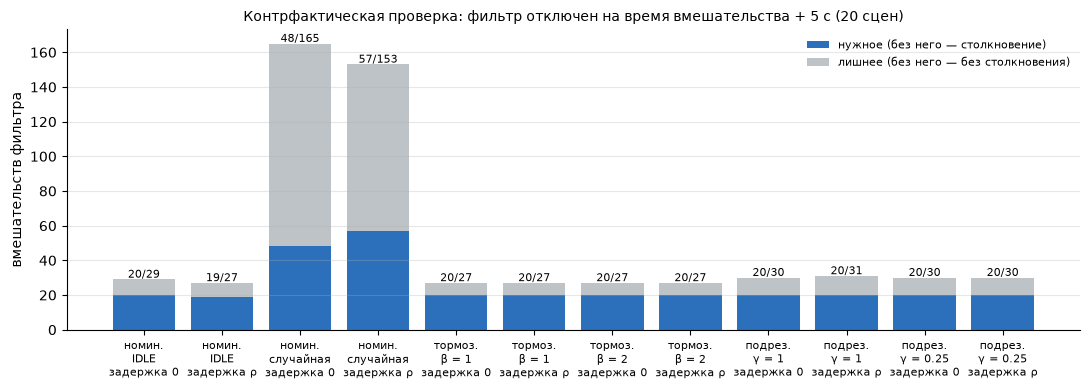

In [5]:
# доля нужных по сценариям и задержкам — столбики «нужные / лишние»
g = cf.groupby(['сценарий', 'level', 'reaction_delay'], sort=False)['needed'].agg(['sum', 'size']).reset_index()
SHORT = {'номинальный, IDLE': 'номин.\nIDLE', 'номинальный, случайная': 'номин.\nслучайная',
         'тормозящий лидер, IDLE': 'тормоз.\nβ = {:g}', 'подрезание, IDLE': 'подрез.\nγ = {:g}'}
g['подпись'] = [SHORT[s].format(l) + f"\nзадержка {'ρ' if d else '0'}"
              for s, l, d in zip(g['сценарий'], g['level'], g['reaction_delay'])]
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(g))
ax.bar(x, g['sum'], color='#2c6fbb', label='нужное (без него — столкновение)')
ax.bar(x, g['size'] - g['sum'], bottom=g['sum'], color='#bdc3c7', label='лишнее (без него — без столкновения)')
for xi, (s, n) in enumerate(zip(g['sum'], g['size'])):
    ax.text(xi, n + 1, f'{s}/{n}', ha='center', fontsize=8)
ax.set_xticks(x, g['подпись'], fontsize=8)
ax.set_ylabel('вмешательств фильтра')
ax.legend(frameon=False, fontsize=8)
ax.set_title(f'Контрфактическая проверка: фильтр отключен на время вмешательства + {CF_HORIZON:g} с (20 сцен)', fontsize=10)
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / '06_counterfactual.png', dpi=150)

Как читать:
- **IDLE** — вмешательства длинные (это слитый «дребезг» за машиной впереди), и большинство нужные: IDLE не тормозит сам, и без фильтра врезается. Лишние у IDLE — в основном короткие торможения в первые секунды из-за стартовой расстановки (см. ниже).
- **Случайная политика** — большая часть вмешательств лишние. В основном это запреты перестроений: перестроение в промежуток меньше d_min нарушает RSS, но к столкновению в ближайшие 5 с приводит не всегда.
- При **β = 2 с задержкой ρ** вмешательства почти все нужные, но не достаточные — столкновение все равно происходит (см. таблицу исходов).

Откуда у IDLE лишние вмешательства: смотрим, когда они начинаются и сколько длятся.

In [6]:
idle = cf[cf['сценарий'].str.contains('IDLE')]
idle.groupby('needed').agg(
    вмешательств=('t_start', 'size'),
    начались_в_первые_3_с=('t_start', lambda t: int((t < 3).sum())),
    медиана_длительности_с=('duration', 'median'),
).rename(index={False: 'лишние', True: 'нужные'})

,вмешательств,начались_в_первые_3_с,медиана_длительности_с
needed,,,
лишние,86,70,0.533333
нужные,199,36,27.533333


Почти все лишние вмешательства IDLE начинаются в первые 3 с и длятся около полсекунды: это реакция на стартовую расстановку highway-env, где машины стоят ближе d_min (этап 5). В основной части эпизода у IDLE вмешательства в основном нужные. Для экспериментов имеет смысл считать вмешательства только после 3 с — так же, как нарушения начинаются не раньше 3 с.

## Пример «лишнего» торможения: исходный прогон и прогон без вмешательства

сценарий       номинальный, случайная
seed                               16
t_start                          23.0
t_end                       30.066667
brake_steps                        46
lc_steps                            4
min_gap                      9.890216
Name: 320, dtype: object

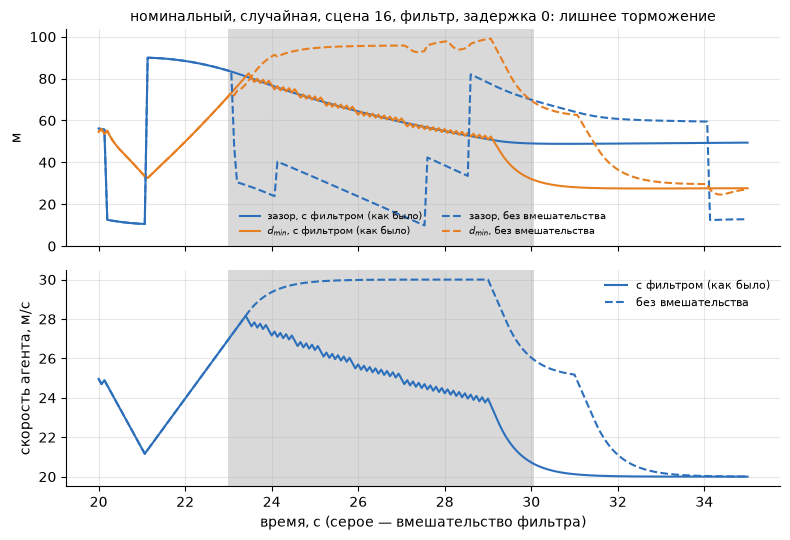

In [7]:
extra = cf[(~cf.needed) & (cf['тип'] == 'торможение') & (cf.duration > 0.5)].sort_values('duration', ascending=False)
ex = extra.iloc[0]
kind, policy, logs = LOGS[ex['сценарий']]
job = (int(ex.seed), ex.level, True, ex.reaction_delay)
orig = logs[job]
_, cf_log = _run_one(job, kind, policy, shield_off_at=ex.t_start, t_stop=ex.t_end + CF_HORIZON)
lo, hi = ex.t_start - 3, ex.t_end + CF_HORIZON
fig, axes = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)
for log, style, name in [(orig, '-', 'с фильтром (как было)'), (cf_log, '--', 'без вмешательства')]:
    w = log[(log.t >= lo) & (log.t <= hi)]
    axes[0].plot(w.t, w.gap.where(w.gap < 1e6), style, color='#2c6fbb', label=f'зазор, {name}')
    axes[0].plot(w.t, w.d_min.where(w.gap < 1e6), style, color='#e67e22', label=f'$d_{{min}}$, {name}')
    axes[1].plot(w.t, w.ego_v, style, color='#2c6fbb', label=name)
for ax in axes:
    ax.axvspan(ex.t_start, ex.t_end, color='0.85', linewidth=0)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('м'); axes[0].set_ylim(bottom=0)
axes[1].set_ylabel('скорость агента, м/с')
axes[1].set_xlabel('время, с (серое — вмешательство фильтра)')
axes[0].legend(fontsize=7, frameon=False, ncol=2)
axes[1].legend(fontsize=8, frameon=False)
axes[0].set_title(f"{ex['сценарий']}, сцена {int(ex.seed)}, {NAMES[(True, ex.reaction_delay)]}: лишнее торможение", fontsize=10)
fig.tight_layout()
fig.savefig(FIG / '06_extra_intervention.png', dpi=150)
ex[['сценарий', 'seed', 't_start', 't_end', 'brake_steps', 'lc_steps', 'min_gap']]

Без вмешательства зазор опускается ниже d_min (по RSS ситуация опасная), но столкновения не происходит: машина впереди не тормозит изо всех сил. Это и есть смысл «лишнего» срабатывания: RSS страхует от худшего случая, который в этот раз не наступил. Поэтому «лишнее» здесь — не ошибка фильтра, а цена гарантии.

## Ограничения этой проверки (для статьи)

1. Окно — время вмешательства + 5 с. Столкновение позже окна не учитывается; при большем окне доля нужных была бы выше.
2. Вмешательства с перерывом меньше 1 с объединены. У IDLE это дает длинные вмешательства (десятки секунд), и вердикт «нужное» относится ко всему отрезку.
3. Контрфакт отвечает на вопрос «было бы столкновение», а не «была бы опасная по RSS ситуация». Второе почти всегда «да» — фильтр срабатывает только при опасности.
4. Политика в контрфакте та же (IDLE или та же последовательность случайных действий). Для PPO надо будет запрашивать политику по наблюдениям контрфактического прогона — `run_episode` это уже позволяет.

## Выводы этапа 6

1. Исходы эпизодов разделены на четыре категории. Новая категория «остановка» важна для сцены с тормозящим лидером: IDLE с фильтром стоит за остановившимся лидером до конца эпизода.
2. Пробег считается по факту и есть в таблице исходов.
3. Контрфактическая проверка работает: у IDLE большинство вмешательств нужные, у случайной политики большинство лишние (в основном запреты перестроений).